In [1]:
# Load modules
import os
import glob
import netCDF4
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.gridspec as gridspec

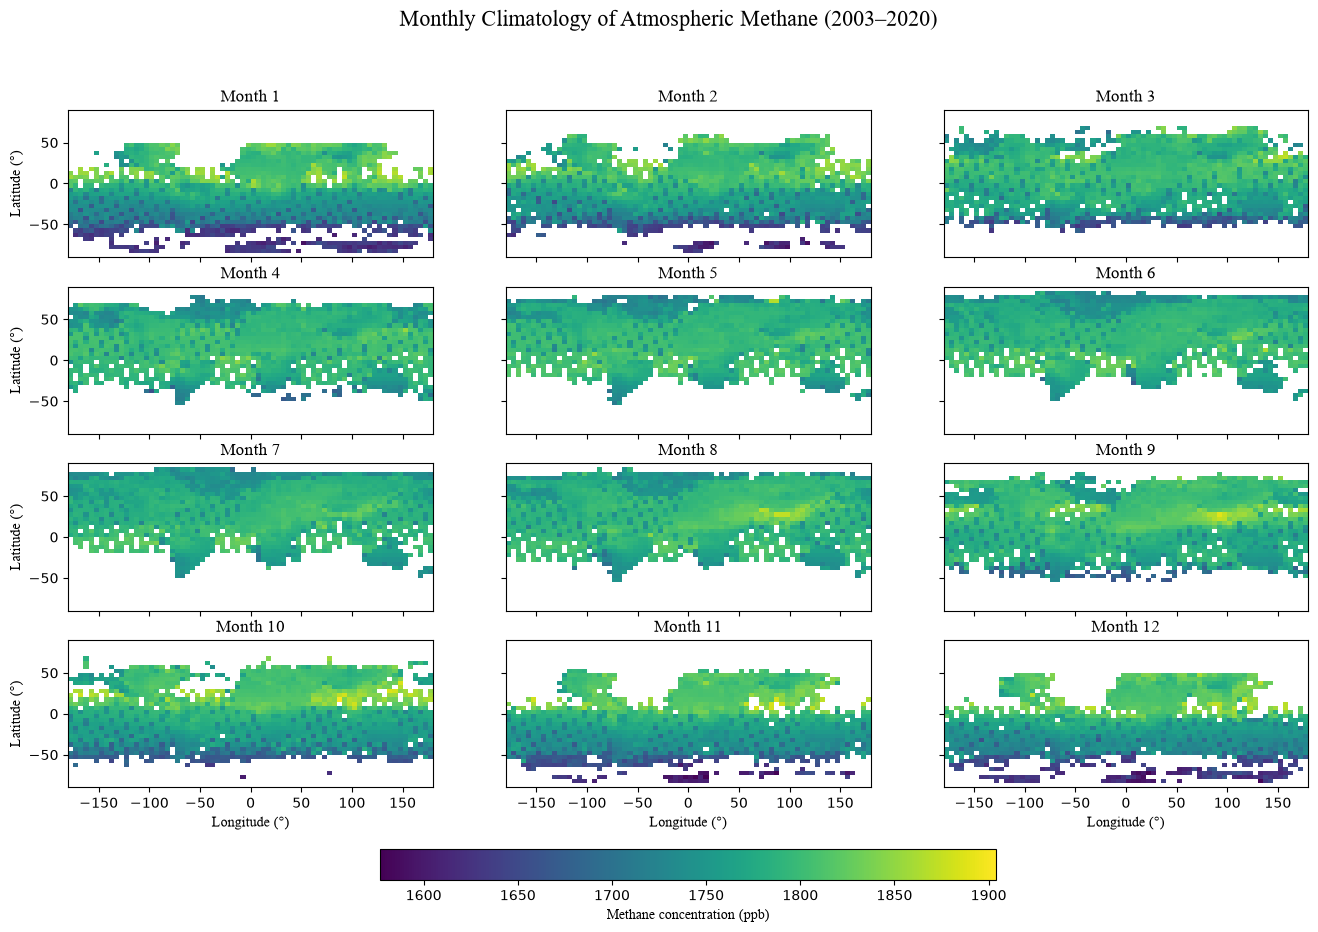

In [2]:
##### PS_1
### 1.1
# 读取文件
data1 = xr.open_dataset(r"..\ESE5023\200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc", engine="netcdf4")
# 提取甲烷浓度去除缺失值并转换单位为 ppb
xch4 = data1['xch4'].where(data1['xch4'] != 1e20) * 1e9

# 计算 climatology
data1_1 = xch4.groupby('time.month').mean(dim='time', skipna=True)

# 绘图
fig, axes = plt.subplots(4, 3, figsize=(16, 10))
# 统一所有子图的颜色范围
vmin = float(data1_1.min())
vmax = float(data1_1.max())
# 绘制甲烷浓度分布
for month, ax in enumerate(axes.flat, start=1):
    im = ax.pcolormesh(data1['lon'], data1['lat'], data1_1.sel(month=month), cmap='viridis', vmin=vmin, vmax=vmax, shading='auto')
    ax.set_title(f'Month {month}', fontname='Times New Roman')
    # 隐藏内部子图的刻度标签只保留刻度线
    ax.label_outer()
    # 最底下一行显示横轴标题
    if ax in axes[-1, :]:
        ax.set_xlabel('Longitude (°)', fontname='Times New Roman')
    # 最左边一列显示纵轴标题
    if ax in axes[:, 0]:
        ax.set_ylabel('Latitude (°)', fontname='Times New Roman')
# 添加色标
cbar = fig.colorbar(im,ax=axes.ravel().tolist(), orientation='horizontal', fraction=0.04, pad=0.08)
cbar.set_label('Methane concentration (ppb)', fontname='Times New Roman')
fig.suptitle('Monthly Climatology of Atmospheric Methane (2003–2020)', fontsize=16, fontname='Times New Roman')
plt.show()

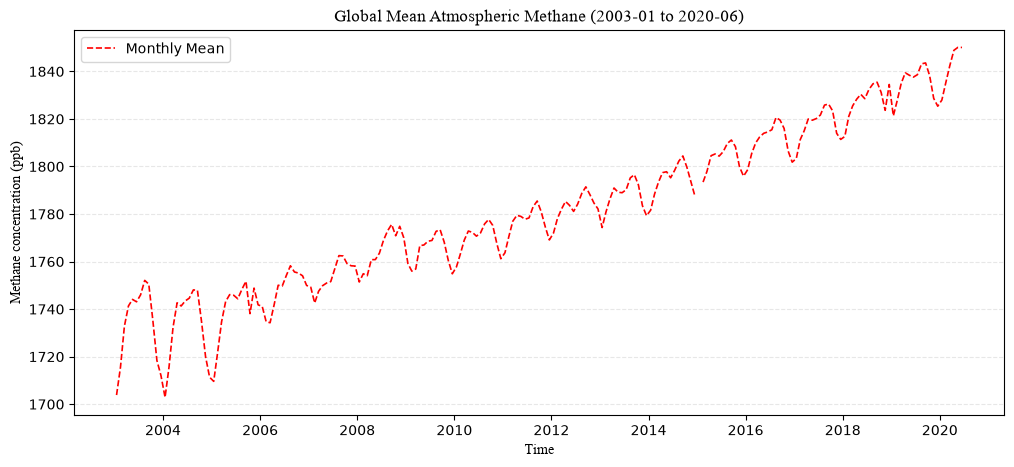

In [2]:
### 1.2
# 计算每个月的全球平均甲烷浓度
data1_2 = xch4.mean(dim=['lat', 'lon'], skipna=True)

# 绘制时间序列图
plt.figure(figsize=(12, 5))
plt.plot(data1['time'], data1_2, 'r--', linewidth=1.2, label="Monthly Mean")
plt.title('Global Mean Atmospheric Methane (2003-01 to 2020-06)', fontname='Times New Roman')
plt.xlabel('Time', fontname='Times New Roman')
plt.ylabel('Methane concentration (ppb)', fontname='Times New Roman')
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend()
plt.show()

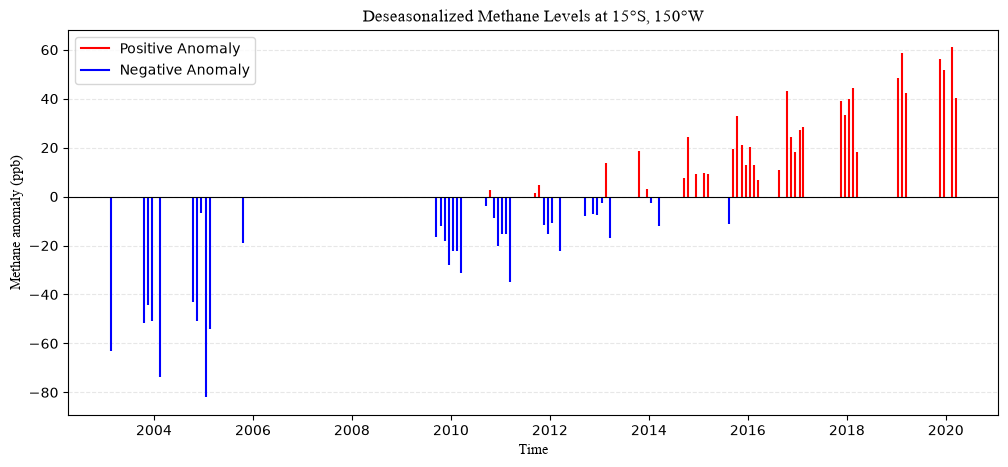

In [6]:
### 1.3
# 提取指定地点的甲烷浓度时间序列
data1_3 = xch4.sel(lat=-15, lon=-150, method='nearest')

# 计算该地点每个月份的多年平均浓度
monthly_mean = data1_3.groupby('time.month').mean(dim='time', skipna=True)

# 去季节化：实际浓度减去对应月份的多年平均浓度
deseasonalized = data1_3.groupby('time.month') - monthly_mean

# 绘制时间序列
plt.figure(figsize=(12, 5))
times = data1_3['time'].values
values = deseasonalized.values
# 正异常为红色，负异常为蓝色
colors = ['red' if deseasonalized >= 0 else 'blue' for deseasonalized in values]
plt.vlines(times, ymin=0, ymax=values, colors=colors)
plt.axhline(y=0, color='black', linewidth=0.8)
plt.title('Deseasonalized Methane Levels at 15°S, 150°W', fontname='Times New Roman')
plt.xlabel('Time', fontname='Times New Roman')
plt.ylabel('Methane anomaly (ppb)', fontname='Times New Roman')
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.plot([], [], color='red', label='Positive Anomaly')
plt.plot([], [], color='blue', label='Negative Anomaly')
plt.legend(loc='upper left')
plt.show()

In [3]:
##### PS_2
### 2.1
# 读取文件
data2 = xr.open_dataset(r"..\ESE5023\NOAA_NCDC_ERSST_v3b_SST.nc", engine="netcdf4")

# 提取SST变量
data2_1 = data2['sst']

# 提取Niño3.4区域
nino34 = data2_1.sel(lat=slice(-5, 5), lon=slice(190, 240))

# 计算SST时间序列
nino34_mean = nino34.mean(dim=['lat', 'lon'], skipna=True)

# 计算月平均气候态
monthly_climatology = (nino34_mean.groupby('time.month').mean(dim='time', skipna=True))

# 计算SST异常值
sst_anomalies = (nino34_mean.groupby('time.month') - monthly_climatology)

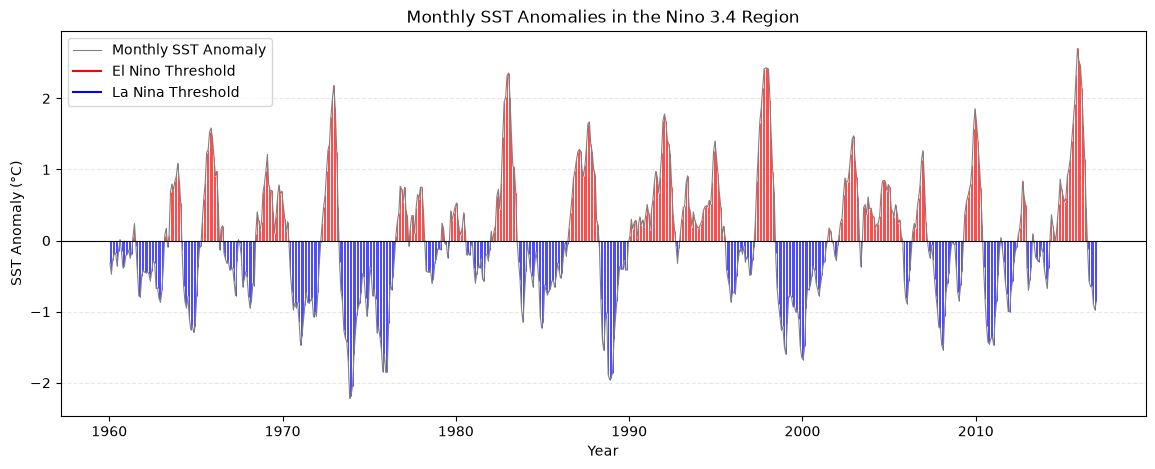

In [8]:
### 2.2
# 绘图
plt.figure(figsize=(14, 5))
values = sst_anomalies.values
times = sst_anomalies['time'].values
# 正异常为红色，负异常为蓝色
colors = ['red' if v >= 0 else 'blue' for v in values]
plt.vlines(times, ymin=0, ymax=values, colors=colors, linewidth=0.5)
plt.plot(times, values, color='grey', linewidth=0.8, label='Monthly SST Anomaly')
plt.axhline(y=0, color='black', linewidth=0.8)
plt.title('Monthly SST Anomalies in the Nino 3.4 Region')
plt.xlabel('Year')
plt.ylabel('SST Anomaly (°C)')
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.plot([], [], color='red', label='El Nino Threshold')
plt.plot([], [], color='blue', label='La Nina Threshold')
plt.legend(loc='upper left')
plt.show()

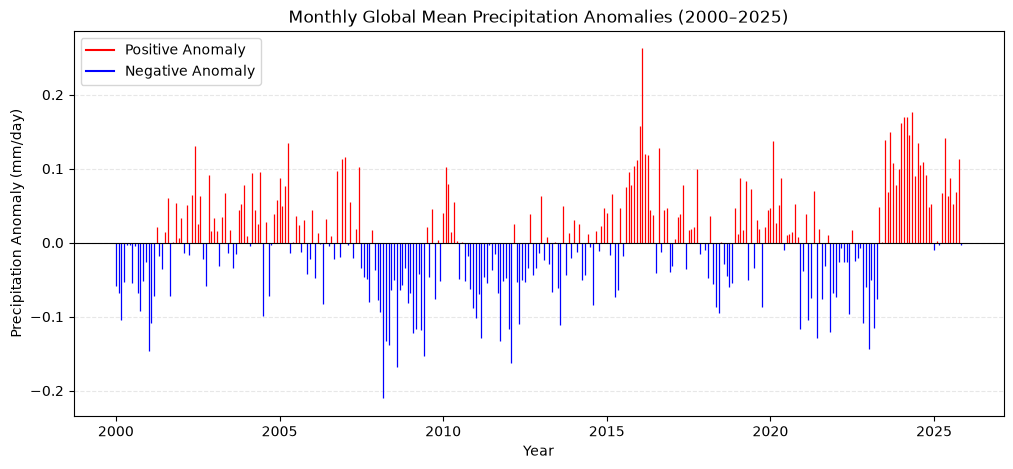

In [4]:
##### PS_3
### 3.1
# 读取文件
folder = r"rainfall"
files = sorted(glob.glob(os.path.join(folder, "*.nc4")))
data3 = xr.open_mfdataset(files, combine="by_coords")

# 提取降水变量
precip = data3["sat_gauge_precip"]

# 按纬度进行面积加权
weights = np.cos(np.deg2rad(data3["lat"]))
global_mean = precip.weighted(weights).mean(dim=("lat", "lon"))

# 年际月平均
global_monthly_climatology = global_mean.groupby("time.month").mean("time")

# 计算距平
precip_anomaly = global_mean.groupby("time.month") - global_monthly_climatology

# 绘图
plt.figure(figsize=(12, 5))
# 提取时间和距平值
times = precip_anomaly["time"].values
values = precip_anomaly.values
colors = ['red' if v >= 0 else 'blue' for v in values]
plt.vlines(times, ymin=0, ymax=values, colors=colors, linewidth=0.9)
plt.axhline(y=0, color='black', linewidth=0.8)
plt.title('Monthly Global Mean Precipitation Anomalies (2000–2025)')
plt.xlabel('Year')
plt.ylabel('Precipitation Anomaly (mm/day)')
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().xaxis.set_major_locator(mdates.YearLocator(5))
plt.plot([], [], color='red', label='Positive Anomaly')
plt.plot([], [], color='blue', label='Negative Anomaly')
plt.legend(loc='upper left')
plt.show()

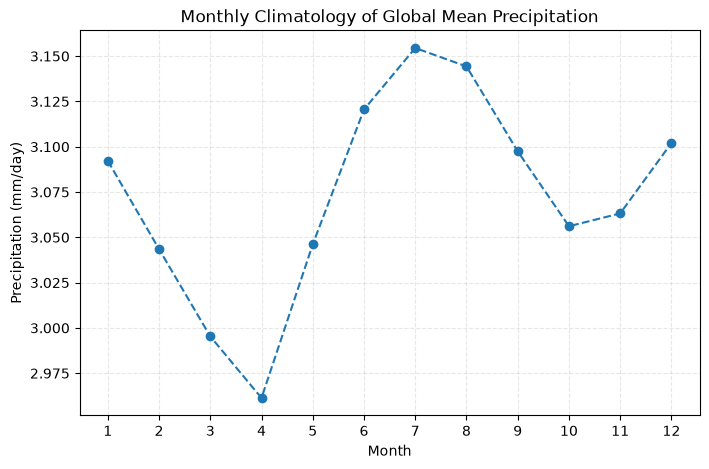

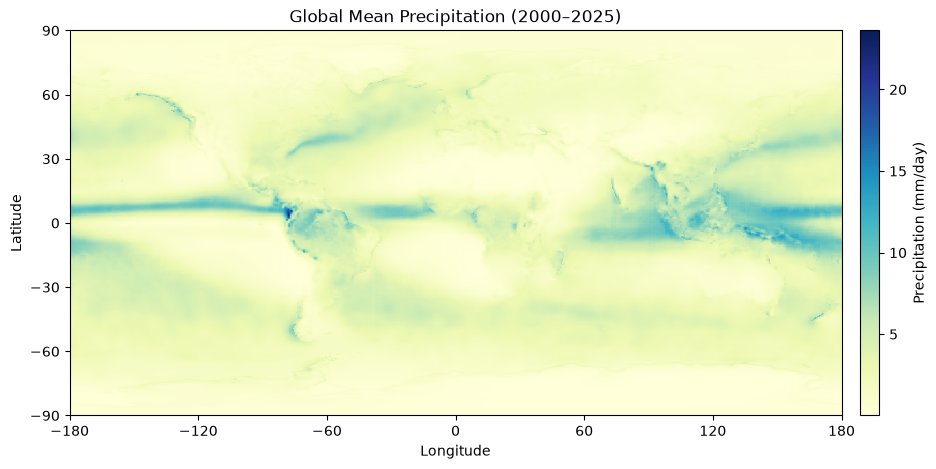

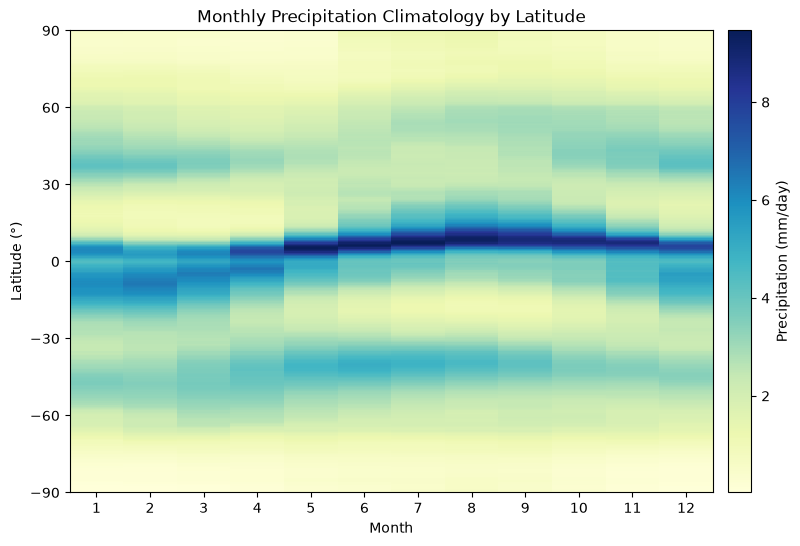

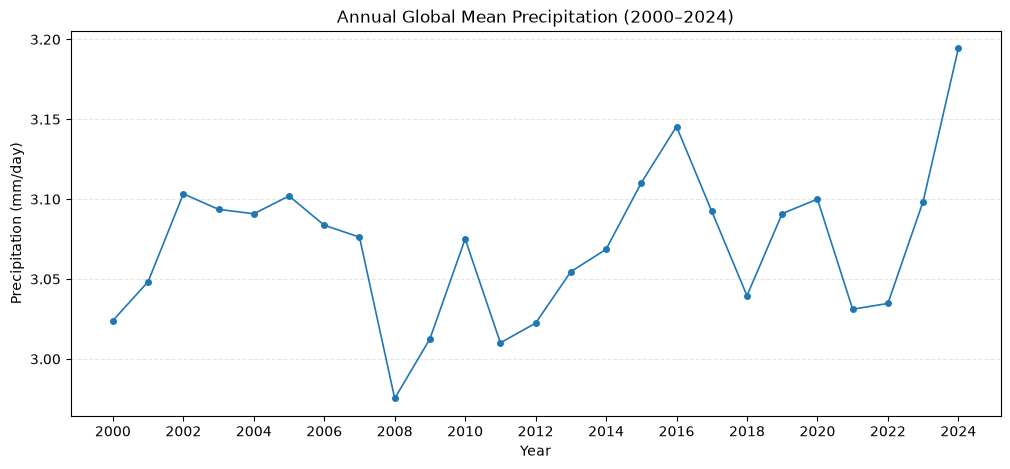

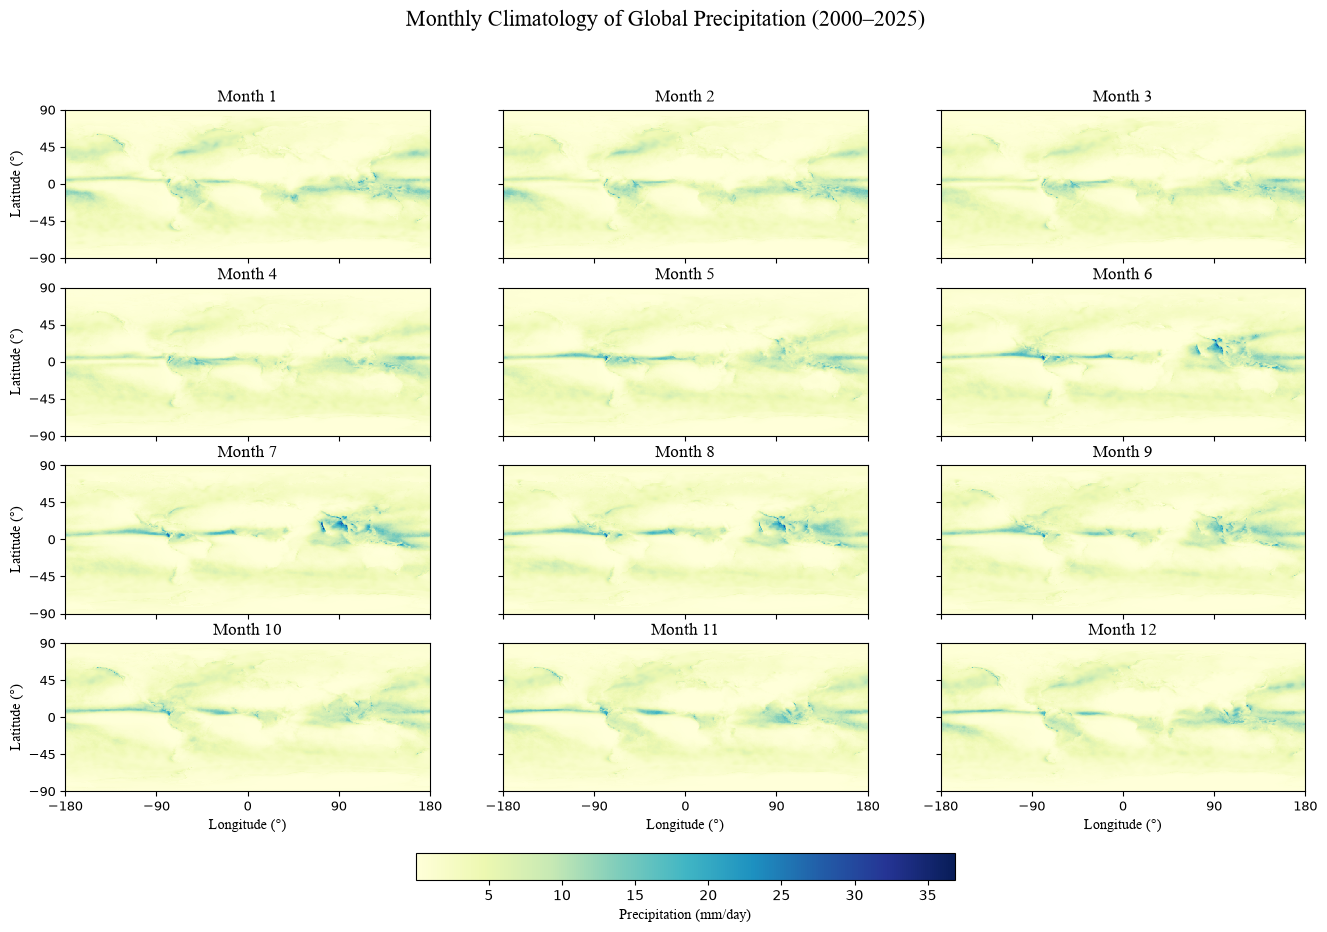

In [10]:
### 3.2
## Plot1全球平均月降水率的季节变化
# 计算各月份的全球面积加权平均降水率
weights = np.cos(np.deg2rad(data3["lat"]))
global_mean = precip.weighted(weights).mean(dim=("lat", "lon"))
monthly_global_mean = global_mean.groupby("time.month").mean("time")

# 绘图
plt.figure(figsize=(8, 5))
plt.plot(monthly_global_mean["month"], monthly_global_mean.values, 'o--', linewidth=1.5)
plt.xticks(np.arange(1, 13))
plt.xlabel("Month")
plt.ylabel("Precipitation (mm/day)")
plt.title("Monthly Climatology of Global Mean Precipitation")
plt.grid(True, linestyle="--", alpha=0.3)
plt.show()

## Plot2全球多年平均降水空间分布
# 计算平均降水率
precip_climatology = precip.mean(dim="time").compute()

# 绘图
plt.figure(figsize=(12, 5))
plt.pcolormesh(precip_climatology["lon"], precip_climatology["lat"], precip_climatology.values, shading="auto", cmap="YlGnBu")
plt.colorbar(label="Precipitation (mm/day)", pad=0.02)
plt.title("Global Mean Precipitation (2000–2025)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.xticks(np.arange(-180, 181, 60))
plt.yticks(np.arange(-90, 91, 30))
plt.show()

## Plot3不同纬度的月降水变化
# 对经度求平均
monthly_climatology = precip.groupby("time.month").mean(dim="time").compute()
lat_month_precip = monthly_climatology.mean(dim="lon")

# 绘图
plt.figure(figsize=(10, 6))
plt.pcolormesh(lat_month_precip["month"], lat_month_precip["lat"], lat_month_precip.values.T, shading="auto", cmap="YlGnBu")
plt.colorbar(label="Precipitation (mm/day)", pad=0.02)
plt.title("Monthly Precipitation Climatology by Latitude")
plt.xlabel("Month")
plt.ylabel("Latitude (°)")
plt.xticks(np.arange(1, 13, 1))
plt.yticks(np.arange(-90, 91, 30))
plt.show()

## Plot4全球年平均降水率时间序列
# 计算年平均
annual_mean = global_mean.groupby("time.year").mean(dim="time")

# 排除不完整的2025年
annual_mean = annual_mean.sel(year=slice(2000, 2024)).compute()

# 绘图
plt.figure(figsize=(12, 5))
plt.plot(annual_mean["year"], annual_mean.values, marker="o", markersize=4, linewidth=1.2)
plt.title("Annual Global Mean Precipitation (2000–2024)")
plt.xlabel("Year")
plt.ylabel("Precipitation (mm/day)")
plt.xticks(np.arange(2000, 2025, 2))
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.show()

## Plot5全球月际降水分布图
# 统一所有子图的颜色范围
vmin = float(monthly_climatology.min())
vmax = float(monthly_climatology.max())

# 绘图
fig, axes = plt.subplots(4, 3, figsize=(16, 10))
for month, ax in enumerate(axes.flat, start=1):
    im = ax.pcolormesh(monthly_climatology["lon"], monthly_climatology["lat"], monthly_climatology.sel(month=month).values, cmap="YlGnBu", vmin=vmin, vmax=vmax, shading="auto")
    ax.set_title(f"Month {month}", fontname="Times New Roman")
    ax.set_xticks(np.arange(-180, 181, 90))
    ax.set_yticks(np.arange(-90, 91, 45))
    ax.tick_params(labelsize=9)
    ax.label_outer()
    if ax in axes[-1, :]:
        ax.set_xlabel("Longitude (°)", fontname="Times New Roman")
    if ax in axes[:, 0]:
        ax.set_ylabel("Latitude (°)", fontname="Times New Roman")
cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="horizontal", fraction=0.035, pad=0.08)
cbar.set_label("Precipitation (mm/day)", fontname="Times New Roman")
fig.suptitle("Monthly Climatology of Global Precipitation (2000–2025)", fontsize=16, fontname="Times New Roman")
plt.show()